# Reading cell-cycle phase from label-free morphology (OPS0077 NTC)

**Why.** Cell-cycle position is one of the biggest drivers of single-cell morphological heterogeneity: two identical
cells can look different only because one is in G1 and the other in G2. If we can read a cell's cell-cycle position from
label-free imaging, we can later regress it out and see what a perturbation actually did.

> ### Two meanings of "phase" - keep them apart
> - **phase-contrast imaging** (label-free phase, QPI): an imaging modality. Here it is the **predictor**, and to avoid
>   confusion we call its features **morphology** below.
> - **cell-cycle phase** (G1 / S / G2 / M, or the continuous circular position `cc_phase`): where a cell sits in the
>   cycle. It is the **target**.
>
> So "predict cell-cycle phase from phase-contrast morphology" is two different things that happen to share the word
> "phase", not circular reasoning. The continuous circular cell-cycle phase is the standard
> [**tricycle**](https://bioc.r-universe.dev/tricycle) representation (Zheng et al.).

**Plan.** (1) DNA content as the 2N->4N backbone. (2) the circular cell-cycle phase axis (`cc_phase`, tricycle-style).
(3) define the ground-truth targets from 4i. (4) predict them from morphology, held-out. All on the **non-targeting
(NTC)** cells, where the only structured variation is the cell cycle. Everything is keyed by `cell_key` = well + 4i
segmentation id, so each cell's 4i readout and its morphology features are the same physical cell.

## The 4i markers and what each one reads (`cell_cycle_markers.md`)

| readout | measures | behaviour through the cycle |
|---|---|---|
| **DNA content** (integrated DAPI) | amount of DNA | 2N in G1, rises through S, 4N in G2/M |
| **pRb** (phospho-Rb) | the restriction point | low in quiescent / early G1, high once committed |
| **pRb / Rb ratio** | fraction of Rb phosphorylated | cleaner commitment signal than pRb alone |
| **nuclear area** | nucleus size | grows into G2 |
| **p21** | CDK inhibitor | higher in G1, degraded in S/G2M; small absolute range and noisy in cycling cells (shown below) |

In [1]:
import os
import numpy as np, pandas as pd, anndata as ad
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, roc_auc_score, roc_curve
import warnings; warnings.filterwarnings('ignore')

def find(n):
    # team compute folder, then common repo locations (the team's cc scores live in cell_cycle_4i_DNA/)
    for r in ['/srv/team/data/crossmodal/ops0077_ntc', 'data', 'cell_cycle_4i_DNA', '.', '..']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

# per-cell cell-cycle frame: one row per NTC cell, 4i cell-cycle readouts aligned on cell_key
fr = pd.read_parquet(find('OPS0077_NTC_cellcycle_frame.parquet'))
rel = (fr['dna_reliable'].astype(str) == 'True').values
print(f'{len(fr):,} NTC cells; {int(rel.sum()):,} with reliable DNA content')
fr.loc[rel, ['cycle_stage','dna_content_log2','log2_pRb','prb_rb_ratio','p21','nuclear_area_4i']].head()

52,189 NTC cells; 36,014 with reliable DNA content


,cycle_stage,dna_content_log2,log2_pRb,prb_rb_ratio,p21,nuclear_area_4i
cell_key,,,,,,
A/1/0|21521877,G2/M,0.858680,8.389548,0.347250,120.541954,241.670013
A/1/0|27047760,G0/G1-early,-0.100527,7.695920,0.218148,123.872581,176.182510
A/1/0|20873972,G1-late,-0.325895,8.901942,0.324129,131.113556,NaN
A/1/0|39951811,G1-late,-0.746649,10.616129,0.993383,124.631805,42.751720
A/1/0|16993631,G2/M,1.073597,8.316174,0.329740,119.867035,373.490021


## Step 1 - DNA content, the 2N / 4N backbone

DNA content = integrated DAPI inside each 4i nucleus, background-subtracted per cell, averaged over the unsaturated
staining rounds (2 to 4), log2 relative to the population median. On that scale **0 = 2N (G1)** and **+1 = 4N (G2/M)**.
An asynchronous population shows a tall G1 peak, an S-phase shoulder, and a G2/M peak one log2 (2x) higher.

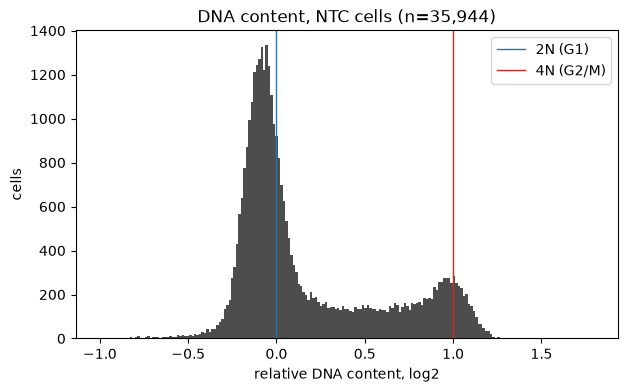

In [2]:
x = fr.loc[rel, 'dna_content_log2'].astype(float).values
x = x[(x > -1) & (x < 1.8)]
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(x, 200, color='0.3'); ax.axvline(0, color='tab:blue', lw=1, label='2N (G1)'); ax.axvline(1, color='tab:red', lw=1, label='4N (G2/M)')
ax.set_xlabel('relative DNA content, log2'); ax.set_ylabel('cells'); ax.legend(); ax.set_title(f'DNA content, NTC cells (n={len(x):,})'); plt.show()

## Step 2 - the cell-cycle phase axis: the team's circular `cc_phase` (tricycle-style)

A cell-cycle axis has to be **circular**: G1 -> S -> G2/M -> M -> back to G1. The team's `cell_cycle_scores.csv` gives
each cell exactly that: a continuous circular **cell-cycle phase** `cc_phase` in [0, 1], built from the 4i markers and
DNA in the style of [tricycle](https://bioc.r-universe.dev/tricycle). We adopt it as the canonical cell-cycle phase.
(We deliberately do **not** build a linear pseudotime: an open G1->G2/M ordering is only half the loop and would
misrepresent the cycle.)

The signature of a correct clock: **DNA content peaks in the middle** (G2/M, 4N) and returns to 2N at **both** ends
(G1 before S, and G1 again after mitosis). We confirm that. p21 runs **anti-phase** to DNA (higher in G1, degraded in
S/G2M), the expected behaviour, though its absolute range is small and noisy.

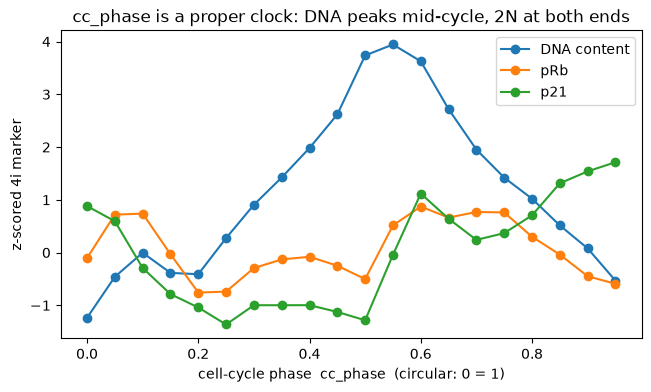

DNA z at clock start / middle / end: -1.24 3.74 -0.53 | p21 spread across clock: 3.08


In [3]:
cc_all = pd.read_csv(find('cell_cycle_scores.csv'))
cc_all = cc_all[(cc_all['dna_reliable']==True) & (cc_all['cc_phase_source']=='dna+pcs')].copy()
cc_all['bin'] = (cc_all['cc_phase']*20).clip(0,19).astype(int)
prof = cc_all.groupby('bin')[['z_dna','z_pRb','z_p21']].mean()
fig, ax = plt.subplots(figsize=(7.5,4))
for col, lab in [('z_dna','DNA content'),('z_pRb','pRb'),('z_p21','p21')]:
    ax.plot(prof.index/20, prof[col], 'o-', label=lab)
ax.set_xlabel('cell-cycle phase  cc_phase  (circular: 0 = 1)'); ax.set_ylabel('z-scored 4i marker'); ax.legend()
ax.set_title('cc_phase is a proper clock: DNA peaks mid-cycle, 2N at both ends'); plt.show()
print('DNA z at clock start / middle / end:', prof['z_dna'].iloc[0].round(2), prof['z_dna'].iloc[10].round(2), prof['z_dna'].iloc[19].round(2),
      '| p21 spread across clock:', round(float(prof['z_p21'].max()-prof['z_p21'].min()),2))

## Step 3 - the ground-truth targets (all from 4i, never from morphology)

We predict three 4i-defined targets. **Morphology is only the predictor; every label is measured on the same cell by
4i.**

**(a) G1 vs G2/M**, a clean binary from DNA content:
```python
g = np.full(len(y_dna), -1)
g[y_dna < 0.25] = 0      # G1   (clearly 2N)
g[y_dna > 0.65] = 1      # G2/M (clearly toward 4N)
# 0.25 to 0.65 (S phase / ambiguous) -> -1, dropped: mid-replication, not a clean either/or
```
**(b) DNA content** (continuous, the log2 value above).
**(c) cell-cycle phase `cc_phase`** (continuous, circular).

In [4]:
# morphology features (phase-contrast OrganelleProfiler) for the same cells
ph = ad.read_h5ad(find('OPS0077_NTC_phase_OrganelleProfiler.h5ad'))
ph.obs_names = ph.obs['cell_key'].astype(str)
cells = fr.index[rel]; cells = cells[cells.isin(ph.obs_names)]
ph = ph[cells]; Fr = fr.loc[cells]
present = np.isfinite(np.asarray(ph.X)).mean(0) >= 0.85            # drop never-populated OrganelleProfiler families
Xm = np.asarray(ph.X, np.float32)[:, present]                      # Xm = morphology (the predictor)
groups = Fr['tile_pheno'].astype(str).values
area = np.c_[Fr.nuclear_area_4i.astype(float), Fr.cell_area_4i.astype(float)]
area = np.where(np.isfinite(area), area, np.nanmedian(area,0))     # cell-size-only baseline

y_dna = Fr.dna_content_log2.astype(float).values
g = np.full(len(y_dna), -1); g[y_dna < 0.25] = 0; g[y_dna > 0.65] = 1
print(f'cells {len(cells):,} | morphology features {int(present.sum())} | tiles {len(set(groups)):,}')
print(f'G1 n={int((g==0).sum()):,} | G2/M n={int((g==1).sum()):,} | S/ambiguous dropped n={int((g==-1).sum()):,}')

cells 36,014 | morphology features 1740 | tiles 5,215
G1 n=25,087 | G2/M n=6,971 | S/ambiguous dropped n=3,956


## Step 4 - predict cell-cycle phase from morphology (held-out)

5-fold cross-validation, **folds grouped by imaging tile** so no tile is split across train and test. Inside each fold
we fit median-impute -> robust-scale -> clip -> PCA(100) on the training cells only. Baselines: **cell size only** and a
**shuffled-label null**. `cc_phase` is circular, so we predict sin and cos of its angle and recover the angle
(circular regression), scoring with circular correlation and median angular error.

In [5]:
def prep(a, b, pca):
    imp = SimpleImputer(strategy='median').fit(a); sc = RobustScaler(quantile_range=(10,90)).fit(imp.transform(a))
    f = lambda Q: np.clip(sc.transform(imp.transform(Q)), -5, 5); A, B = f(a), f(b)
    if pca and A.shape[1] > 100: p = PCA(100, random_state=0).fit(A); A, B = p.transform(A), p.transform(B)
    return A, B

def oof_r2(X, y, pca=True):
    pred = np.zeros_like(y)
    for a, b in GroupKFold(5).split(X, y, groups):
        A, B = prep(X[a], X[b], pca); pred[b] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(A, y[a]).predict(B)
    return r2_score(y, pred), pred

def oof_auc(X, gg0, pca=True, shuffle=False):
    m = gg0 >= 0; X2, gg, gr2 = X[m], gg0[m], groups[m]
    if shuffle: gg = np.random.default_rng(0).permutation(gg)
    pp = np.zeros(len(gg))
    for a, b in GroupKFold(5).split(X2, gg, gr2):
        A, B = prep(X2[a], X2[b], pca); pp[b] = LogisticRegression(C=.1, max_iter=3000).fit(A, gg[a]).predict_proba(B)[:,1]
    return roc_auc_score(gg, pp), gg, pp

r_dna, pred_dna = oof_r2(Xm, y_dna); r_dna_sz, _ = oof_r2(area, y_dna, pca=False)
auc, gg, pp = oof_auc(Xm, g); auc_sz, _, _ = oof_auc(area, g, pca=False); auc_null, _, _ = oof_auc(Xm, g, shuffle=True)
pd.DataFrame([
  {'target':'G1 vs G2/M (AUC)', 'from morphology':round(auc,3), 'cell-size baseline':round(auc_sz,3), 'shuffled null':round(auc_null,3)},
  {'target':'DNA content (R2)', 'from morphology':round(r_dna,3), 'cell-size baseline':round(r_dna_sz,3), 'shuffled null':0.0},
])

,target,from morphology,cell-size baseline,shuffled null
0,G1 vs G2/M (AUC),0.935,0.748,0.499
1,DNA content (R2),0.481,0.156,0.000


In [6]:
# circular cell-cycle phase (cc_phase) from morphology, on the cells that have a defined clock
cc = pd.read_csv(find('cell_cycle_scores.csv')).set_index('cell_key')
cc = cc[(cc['dna_reliable']==True) & (cc['cc_phase_source']=='dna+pcs')]
com = ph.obs_names[ph.obs_names.isin(cc.index)]
Xc = np.asarray(ph[com].X, np.float32)[:, present]; cc = cc.loc[com]
th = (cc['cc_phase'].astype(float).values % 1.0) * 2*np.pi
grc = ph[com].obs['tile_pheno'].astype(str).values
arc = np.c_[cc['nuc_area_px'].astype(float), cc['dapi_log_area'].astype(float)]; arc = np.where(np.isfinite(arc), arc, np.nanmedian(arc,0))

def predict_angle(X, th, g, pca=True, shuffle=False):
    if shuffle: th = np.random.default_rng(0).permutation(th)
    s, co = np.sin(th), np.cos(th); ps = np.zeros(len(th)); pc = np.zeros(len(th))
    for a, b in GroupKFold(5).split(X, th, g):
        A, B = prep(X[a], X[b], pca)
        ps[b] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(A, s[a]).predict(B)
        pc[b] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(A, co[a]).predict(B)
    return np.arctan2(ps, pc)

def circ_corr(a, b):
    a0 = a - np.angle(np.mean(np.exp(1j*a))); b0 = b - np.angle(np.mean(np.exp(1j*b)))
    return np.sum(np.sin(a0)*np.sin(b0)) / np.sqrt(np.sum(np.sin(a0)**2)*np.sum(np.sin(b0)**2))

pred_ang = predict_angle(Xc, th, grc)
rows = []
for nm, p in [('morphology', pred_ang), ('cell-size baseline', predict_angle(arc, th, grc, pca=False)),
              ('shuffled null', predict_angle(Xc, th, grc, shuffle=True))]:
    e = np.abs(np.angle(np.exp(1j*(th-p))))*180/np.pi
    rows.append(dict(predictor=nm, circular_r=round(circ_corr(th,p),3), median_angular_error_deg=round(float(np.median(e)),1), within_45deg=round(float((e<45).mean()),2)))
pd.DataFrame(rows)

,predictor,circular_r,median_angular_error_deg,within_45deg
0,morphology,0.489,29.6,0.67
1,cell-size baseline,0.222,43.3,0.51
2,shuffled null,-0.021,53.7,0.45


### Figures

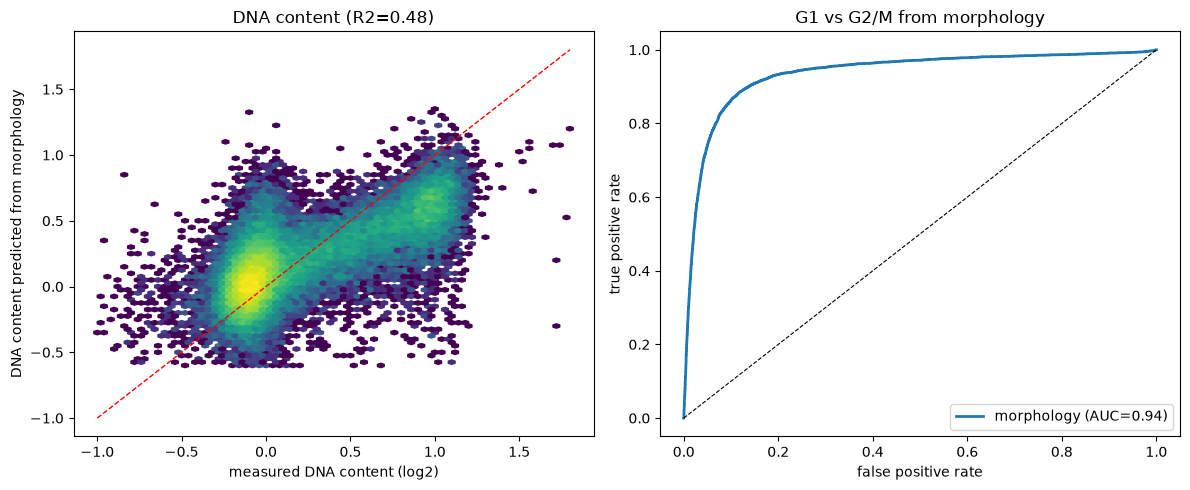

In [7]:
# (1) binary + DNA content from morphology
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].hexbin(y_dna, pred_dna, gridsize=70, bins='log', extent=(-1,1.8,-.6,1.4)); ax[0].plot([-1,1.8],[-1,1.8],'r--',lw=1)
ax[0].set_xlabel('measured DNA content (log2)'); ax[0].set_ylabel('DNA content predicted from morphology'); ax[0].set_title(f'DNA content (R2={r_dna:.2f})')
fpr, tpr, _ = roc_curve(gg, pp); ax[1].plot(fpr, tpr, lw=2, label=f'morphology (AUC={auc:.2f})'); ax[1].plot([0,1],[0,1],'k--',lw=.8)
ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate'); ax[1].set_title('G1 vs G2/M from morphology'); ax[1].legend(); plt.tight_layout(); plt.show()

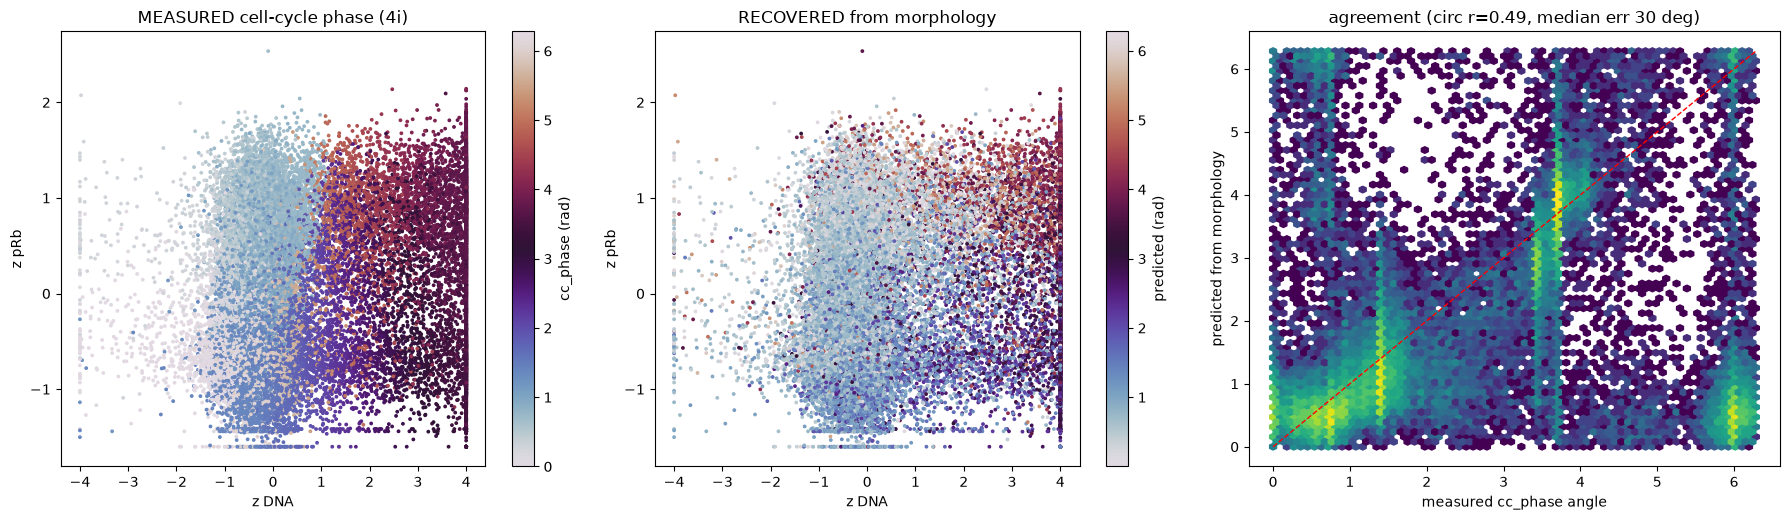

In [8]:
# (2) the circular clock, measured vs recovered from morphology, shown in DNA x pRb space
err = np.abs(np.angle(np.exp(1j*(th-pred_ang))))*180/np.pi
fig, ax = plt.subplots(1,3, figsize=(18,5.3))
s0 = ax[0].scatter(cc['z_dna'], cc['z_pRb'], c=th, s=3, cmap='twilight'); plt.colorbar(s0, ax=ax[0], label='cc_phase (rad)')
ax[0].set_title('MEASURED cell-cycle phase (4i)'); ax[0].set_xlabel('z DNA'); ax[0].set_ylabel('z pRb')
s1 = ax[1].scatter(cc['z_dna'], cc['z_pRb'], c=np.mod(pred_ang,2*np.pi), s=3, cmap='twilight'); plt.colorbar(s1, ax=ax[1], label='predicted (rad)')
ax[1].set_title('RECOVERED from morphology'); ax[1].set_xlabel('z DNA'); ax[1].set_ylabel('z pRb')
ax[2].hexbin(th, np.mod(pred_ang,2*np.pi), gridsize=70, bins='log', extent=(0,2*np.pi,0,2*np.pi)); ax[2].plot([0,2*np.pi],[0,2*np.pi],'r--',lw=1)
ax[2].set_xlabel('measured cc_phase angle'); ax[2].set_ylabel('predicted from morphology'); ax[2].set_title(f'agreement (circ r={circ_corr(th,pred_ang):.2f}, median err {np.median(err):.0f} deg)')
plt.tight_layout(); plt.show()

## Write the per-cell morphology prediction back into the dataset

Each cell gets an out-of-fold `morph_predicted_dna` (held-out), the morphology-based cell-cycle readout for the
cycle-regression (correction) step next.

In [9]:
pred_full = pd.Series(np.nan, index=cells); pred_full[:] = pred_dna
mm = find('OPS0077_NTC_Multimodal_4i_Phase_DNA.h5ad')
A = ad.read_h5ad(mm)
A.obs['morph_predicted_dna'] = pred_full.reindex(A.obs_names).values
try:
    A.write_h5ad(mm, compression='gzip'); out = mm
except Exception:
    out = 'OPS0077_NTC_Multimodal_4i_Phase_DNA_withpred.h5ad'; A.write_h5ad(out, compression='gzip')
print('wrote', out, '| cells with a prediction', int(np.isfinite(A.obs['morph_predicted_dna'].astype(float)).sum()))

wrote /srv/team/data/crossmodal/ops0077_ntc/OPS0077_NTC_Multimodal_4i_Phase_DNA.h5ad | cells with a prediction 36014


## Takeaways

- **Morphology (label-free phase-contrast) reads cell-cycle phase.** Held-out, folds grouped by tile:
  - **G1 vs G2/M: AUC ~0.94** (cell size alone ~0.75; shuffled null ~0.50),
  - **DNA content: R2 ~0.5**,
  - **full circular cell-cycle phase `cc_phase`: circular r ~0.49, median angular error ~30 deg** (size ~43 deg, null ~53 deg).
- **The cell-cycle axis is circular** (the team's tricycle-style `cc_phase`: DNA peaks mid-cycle, 2N at both ends). We do
  not use a linear pseudotime. Morphology is strongest at the clean 2N-vs-4N split and weakest at the two low-DNA ends of
  the clock (early-G1 vs post-mitotic G1), which differ mainly in pRb.
- **p21** runs anti-phase to DNA (higher in G1, degraded in S/G2M) but has a small, noisy absolute range in cycling
  cells, so it is a weak cell-cycle marker here (consistent with the team finding it weak in PCA).
- **"phase" is two things:** the predictor is phase-contrast *morphology*; the target is *cell-cycle* phase. They are
  independent (ground truth is 4i, scored out-of-fold).
- **Next:** regress the morphology-predicted cell-cycle phase out of the representation and test whether a known
  cell-cycle-arresting knockout looks cleaner after correction.

Scope: NTC cells of one screen (OPS0077); DNA trusted on ~36k cells; all data public Biohub OPS0077 (ops0144_20260406).